# [S II] doublet ratio in SF and NSF regions by infall stage - 2026-10-27

Compare corrected **[S II] lambda6716 / lambda6731** flux ratios in SF and NSF
regions across Pre-peak, Close-to-peak and Post-peak infall stages. The products
name the denominator `SII6730`. Adapted from
`20261026_check_intrinsic_NII6583_dispersion_by_global_mass.ipynb`.
There is no global stellar-mass selection or stratification.

Keep the source inclination <80 degrees, finite SNR_POSTFIT >25, finite local
stellar surface density and gas BIN_ID, and MASK==0. SF requires finite HII SFR,
EW(Halpha)>6 Angstrom and finite positive intrinsic Halpha sigma<45 km/s.
ND fails either source Balmer detection threshold; NSF is the remaining usable
population after SF and ND. ND is excluded from all ratio samples.

For **both** SII lines require finite raw flux/error, error>0, raw flux/error
>=CUT_SN, raw flux>=NOISE, and finite positive corrected flux. The thresholds
come from each gas product header. Apply the identical doublet gate to SF,
NSF. Retain ratios outside nominal density-sensitive ranges; report them for QC.
No electron-density conversion or line-ratio clipping is applied.

Profiles use shared 0.25-wide bins over the full finite coordinate ranges;
display local log Sigma_star=6-11 and R/Re=0-2. A product/category/bin needs
>=50 common usable spaxels and >=20 doublet-detected spaxels in that category.
The 50-spaxel gate uses the common SF+NSF+ND population, as in the source;
the 20-spaxel gate is evaluated separately for SF and NSF. Categories can
therefore have different contributing products in a given bin.

Two estimators retain the source paired-flux convention: **equal-galaxy** is
the ratio of the average galaxy mean 6716 flux to the average galaxy mean 6731
flux; **pooled-spaxel** is summed 6716 flux / summed 6731 flux. Neither is the
arithmetic mean of individual spaxel ratios; even the first estimator is not
the arithmetic mean of galaxy ratios. Both lines use identical spaxels.

Bands are the 16th-84th percentiles of 10,000 whole-product bootstrap draws
within each stage. Draws are shared between SF/NSF and coordinate bins within
each estimator; support is applied after resampling. These bands represent
between-product sampling, not propagated line-flux measurement errors.
Single-product bins cannot measure between-galaxy scatter; their bands are
left blank and support counts are reported. Unsupported bins remain NaN.
NGC4567_8 remains one product/bootstrap unit with minimum component R/Re.

Each estimator has a 2x2 figure: SF and NSF rows, local stellar surface density
and radius columns, with all three infall stages overlaid and shared y axes.
FITS inputs and the source notebook are read only. Optional PNG/PDF export
is disabled by default.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
OUTPUT_DIR = PROJECT_ROOT / '20261027_SII_doublet_ratio_SF_NSF_by_stage_assets'
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
SNR_POSTFIT_MIN = 25.0
INCLINATION_MAX = 80.0
EW_MIN, SIGMA_MAX = 6.0, 45.0
PROFILE_X_LIMITS = {'log_sigma_star': (6.0, 11.0), 'radius_re': (0.0, 2.0)}
PROFILE_BIN_WIDTH = 0.25
FRACTION_EDGES = {}
FRACTION_MIN_USABLE = 50
RATIO_MIN_PIXELS = 20
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
STAGE_LABELS = {1: 'Pre-peak', 2: 'Close-to-peak', 3: 'Post-peak'}
STAGE_COLORS = {1: '#2166ac', 2: '#1a9850', 3: '#d73027'}
CATEGORIES = ('SF', 'NSF')
SII_SATURATION_RATIO = 1.4323317191084541  # Lookup: Te=10000 K, ne=20 cm^-3
# Histogram probabilities per bin, not probability density per unit ratio.
RATIO_HIST_EDGES = np.arange(0.0, 2.0 + 0.0125, 0.025)
RATIO_HIST_X_LIMITS = (1.6, 0.4)  # high ratio to low ratio, as requested
RATIO_HIST_LOG_LIMITS = (-5.0, 0.0)
SAVE_FIGURES = False
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 11, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def save_figure(fig, stem):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ('png', 'pdf'):
            fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', dpi=200, bbox_inches='tight')

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

# Authoritative stage/geometry join; combined components must agree in stage.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip():int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int),geometry.mauve_infall_stage.astype(int))


def ratio_histogram_parts(values, radii, edges):
    """Count all/inner/outer samples with an auditable finite histogram window."""
    values, radii = np.asarray(values), np.asarray(radii)
    assert values.shape == radii.shape
    assert np.isfinite(values).all() and (values > 0).all()
    assert np.isfinite(radii).all()
    selections = {'all': np.ones(values.shape, dtype=bool),
                  'inner': radii < 1.0, 'outer': radii >= 1.0}
    result = {}
    for region, select in selections.items():
        v = values[select]
        hist = np.histogram(v, bins=edges)[0]
        below, above = int((v < edges[0]).sum()), int((v > edges[-1]).sum())
        assert int(hist.sum()) + below + above == len(v)
        result[region] = dict(hist=hist, N_region=len(v), N_below_grid=below, N_above_grid=above)
    assert np.array_equal(result['all']['hist'], result['inner']['hist'] + result['outer']['hist'])
    assert result['all']['N_region'] == result['inner']['N_region'] + result['outer']['N_region']
    return result



# Separate one-dimensional splits, not a joint 4x4 mass-radius selection.
STRATUM_LABELS = {
    'log_sigma_star': (r'$\log\Sigma_*<7.5$', r'$7.5\leq\log\Sigma_*<8.5$',
                      r'$8.5\leq\log\Sigma_*\leq9.5$', r'$\log\Sigma_*>9.5$'),
    'radius_re': (r'$0\leq R/R_e<0.5$', r'$0.5\leq R/R_e<1$',
                  r'$1\leq R/R_e\leq1.5$', r'$R/R_e>1.5$'),
}

def spatial_stratum_masks(variable, values):
    values = np.asarray(values)
    assert np.isfinite(values).all()
    if variable == 'log_sigma_star':
        masks = (values < 7.5, (values >= 7.5) & (values < 8.5),
                 (values >= 8.5) & (values <= 9.5), values > 9.5)
    elif variable == 'radius_re':
        assert (values >= 0).all()
        masks = ((values >= 0) & (values < 0.5), (values >= 0.5) & (values < 1.0),
                 (values >= 1.0) & (values <= 1.5), values > 1.5)
    else:
        raise ValueError(variable)
    assert np.all(np.sum(masks, axis=0) == 1), 'Strata must partition the selected sample'
    return masks

## Load the common selection and doublet detections
Preserve source classification and geometry; evaluate SII support separately in SF and NSF.

In [3]:
product_meta = {}
for galid, components in geometry.groupby('notebook_product_id'):
    assert components.stage_code.nunique()==1, f'{galid}: inconsistent component stages'
    incl = components.inclination_deg.to_numpy(float)
    product_meta[galid] = dict(stage=int(components.stage_code.iloc[0]),
        inclination=float(incl.max()),
        inclination_ok=bool(np.isfinite(incl).all() and (incl<INCLINATION_MAX).all()))
inventory_rows, count_rows, ratio_rows, provenance_rows, histogram_rows, stratified_histogram_rows = [], [], [], [], [], []
for folder in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and not p.name.endswith('_logs')):
    gal = folder.name  # preserves combined IDs such as NGC4567_8
    paths = {
        'mass': first_existing(folder, [f'{gal}_spatial_binning_maps_further.fits', f'{gal}_SPATIAL_BINNING_maps_further.fits']),
        'gas': first_existing(folder, [f'{gal}_gas_bin_maps_further.fits', f'{gal}_gas_BIN_maps_further.fits']),
        'ew': first_existing(folder, [f'{gal}_proxy_EW_maps_further.fits', f'{gal}_proxy_EW_maps.fits']),
        'sfh': first_existing(folder, [f'{gal}_sfh_maps.fits']),
        'mask': first_existing(folder, [f'{gal}_mask.fits']),
    }
    if gal not in product_meta:
        raise KeyError(f'{gal}: no authoritative inclination/stage metadata')
    meta = product_meta[gal]
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))

inventory = pd.DataFrame(inventory_rows)
# Shared bins span every finite mass/radius value in included product maps.
# No mass or radius selection is applied to the ratio profiles.
profile_bounds = {key: [np.inf, -np.inf] for key in ('log_sigma_star', 'radius_re')}
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    mass_for_edges, header_for_edges = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    radius_for_edges = calculate_deprojected_radius(
        mass_for_edges.shape, header_for_edges,
        geometry.loc[geometry.notebook_product_id.eq(record.galaxy)])
    for variable, values in (('log_sigma_star', mass_for_edges), ('radius_re', radius_for_edges)):
        finite = values[np.isfinite(values)]
        if finite.size:
            profile_bounds[variable][0] = min(profile_bounds[variable][0], float(finite.min()))
            profile_bounds[variable][1] = max(profile_bounds[variable][1], float(finite.max()))
for variable, (lower, upper) in profile_bounds.items():
    if not np.isfinite([lower, upper]).all():
        raise ValueError(f'{variable}: no finite profile coordinates')
    first_bin = int(np.floor(lower / PROFILE_BIN_WIDTH))
    # Final edge is strictly above the maximum, including exact edge values.
    last_bin = int(np.floor(upper / PROFILE_BIN_WIDTH)) + 1
    FRACTION_EDGES[variable] = np.arange(first_bin, last_bin + 1) * PROFILE_BIN_WIDTH
del mass_for_edges, radius_for_edges
print('Full-range profile bin edges:', {key: (edges[0], edges[-1]) for key, edges in FRACTION_EDGES.items()})

for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    meta = product_meta[gal]
    paths = {key: Path(getattr(record, key)) for key in ('mass', 'gas', 'ew', 'sfh', 'mask')}
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'SII6716_FLUX', 'SII6716_FLUX_ERR', 'SII6716_FLUX_CORR',
            'SII6730_FLUX', 'SII6730_FLUX_ERR', 'SII6730_FLUX_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0)
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    radius_re = calculate_deprojected_radius(mass.shape,mass_hdr,geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    # Preserve the source Halpha-based SF/ND/NSF classification.
    ha_sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    ha_sigma = np.sqrt(np.where(np.isfinite(ha_sigma2) & (ha_sigma2 > 0), ha_sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(ha_sigma) & (ha_sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))



    doublet_ok = np.ones(mass.shape, dtype=bool)
    fluxes = []
    for line in ('SII6716', 'SII6730'):
        raw, err, corr = (arrays[line + suffix] for suffix in ('_FLUX', '_FLUX_ERR', '_FLUX_CORR'))
        with np.errstate(divide='ignore', invalid='ignore'):
            doublet_ok &= (np.isfinite(raw) & np.isfinite(err) & (err > 0)
                           & (raw / err >= sn_cut) & (raw >= floor)
                           & np.isfinite(corr) & (corr > 0))
        fluxes.append(corr)
    ratio = np.full(mass.shape, np.nan)
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        ratio[doublet_ok] = fluxes[0][doublet_ok] / fluxes[1][doublet_ok]
    doublet_ok &= np.isfinite(ratio) & (ratio > 0)
    count = dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                 usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()), NSF=int(nsf.sum()))
    provenance_rows.append(dict(galaxy=gal, CUT_SN=sn_cut, NOISE=floor,
        DUSTLAW=hdr.get('DUSTLAW', 'not recorded'), gas_path=str(paths['gas'])))
    for category, category_mask in (('SF', sf), ('NSF', nsf)):
        selected = category_mask & doublet_ok
        count['N_ratio_' + category] = int(selected.sum())
        count['N_ratio_above_1p5_' + category] = int((selected & (ratio > 1.5)).sum())
        count['N_ratio_below_0p4_' + category] = int((selected & (ratio < 0.4)).sum())
        parts = ratio_histogram_parts(ratio[selected], radius_re[selected], RATIO_HIST_EDGES)
        for region, part in parts.items():
            histogram_rows.append(dict(galaxy=gal, stage=meta['stage'], category=category,
                region=region, N_total=int(selected.sum()),
                N_outside_display=int(((ratio[selected] < min(RATIO_HIST_X_LIMITS))
                    | (ratio[selected] > max(RATIO_HIST_X_LIMITS))).sum()), **part))

        for split_variable, coordinates in (('log_sigma_star', mass), ('radius_re', radius_re)):
            stratum_masks = spatial_stratum_masks(split_variable, coordinates[selected])
            selected_ratios = ratio[selected]
            for stratum, stratum_mask in enumerate(stratum_masks):
                v = selected_ratios[stratum_mask]
                hist = np.histogram(v, bins=RATIO_HIST_EDGES)[0]
                below = int((v < RATIO_HIST_EDGES[0]).sum())
                above = int((v > RATIO_HIST_EDGES[-1]).sum())
                assert hist.sum() + below + above == len(v)
                stratified_histogram_rows.append(dict(galaxy=gal, stage=meta['stage'], category=category,
                    variable=split_variable, stratum=stratum, hist=hist, N_total=len(v),
                    N_parent=int(selected.sum()), N_below_grid=below, N_above_grid=above,
                    N_outside_display=int(((v < min(RATIO_HIST_X_LIMITS))
                                          | (v > max(RATIO_HIST_X_LIMITS))).sum())))
        for variable, values in (('log_sigma_star', mass), ('radius_re', radius_re)):
            edges = FRACTION_EDGES[variable]
            n_valid, _ = np.histogram(values[valid], bins=edges)
            n_category, _ = np.histogram(values[category_mask], bins=edges)
            n_ratio, _ = np.histogram(values[selected], bins=edges)
            sums = [np.histogram(values[selected], bins=edges, weights=flux[selected])[0]
                    for flux in fluxes]
            assert n_ratio.sum() == selected.sum()
            assert np.all(n_ratio <= n_category) and np.all(n_category <= n_valid)
            for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
                ratio_rows.append(dict(galaxy=gal, stage=meta['stage'], category=category,
                    variable=variable, left=lo, right=hi, center=(lo + hi) / 2,
                    N_valid=int(n_valid[j]), N_category=int(n_category[j]), N_ratio=int(n_ratio[j]),
                    sum_primary=float(sums[0][j]), sum_secondary=float(sums[1][j]),
                    mean_primary=float(sums[0][j] / n_ratio[j]) if n_ratio[j] else np.nan,
                    mean_secondary=float(sums[1][j] / n_ratio[j]) if n_ratio[j] else np.nan,
                    supported=bool(n_valid[j] >= FRACTION_MIN_USABLE and n_ratio[j] >= RATIO_MIN_PIXELS)))
    count_rows.append(count)
    print(f'{gal}: {count["N_ratio_SF"]:,} SF and {count["N_ratio_NSF"]:,} NSF doublet detections', flush=True)

counts = pd.DataFrame(count_rows)
ratio_by_galaxy = pd.DataFrame(ratio_rows)
provenance = pd.DataFrame(provenance_rows)
assert len(counts), 'No complete included products'
assert (counts.usable == counts.SF + counts.ND + counts.NSF).all()
assert counts.inclination.lt(INCLINATION_MAX).all()
assert (counts.N_ratio_SF <= counts.SF).all() and (counts.N_ratio_NSF <= counts.NSF).all()
display(inventory[['galaxy', 'stage', 'inclination', 'status']])
display(counts)
display(provenance)
display(counts.groupby('stage')[['usable', 'SF', 'ND', 'NSF', 'N_ratio_SF', 'N_ratio_NSF']].sum().rename(index=STAGE_LABELS))
print('Independent products by stage:', counts.groupby('stage').size().rename(index=STAGE_LABELS).to_dict())
ratio_histograms_by_galaxy = pd.DataFrame(histogram_rows)

stratified_histograms_by_galaxy = pd.DataFrame(stratified_histogram_rows)

Full-range profile bin edges: {'log_sigma_star': (np.float64(5.75), np.float64(11.25)), 'radius_re': (np.float64(0.0), np.float64(12.25))}
IC3392: 13,888 SF and 6,512 NSF doublet detections
NGC4064: 3,273 SF and 26,106 NSF doublet detections
NGC4189: 80,517 SF and 33,542 NSF doublet detections
NGC4254: 465,623 SF and 158,798 NSF doublet detections
NGC4293: 471 SF and 35,773 NSF doublet detections
NGC4294: 67,512 SF and 50,492 NSF doublet detections
NGC4298: 134,035 SF and 34,685 NSF doublet detections
NGC4321: 371,493 SF and 279,081 NSF doublet detections
NGC4351: 29,731 SF and 16,682 NSF doublet detections
NGC4380: 34,550 SF and 22,717 NSF doublet detections
NGC4383: 14,521 SF and 36,703 NSF doublet detections
NGC4394: 24,187 SF and 18,417 NSF doublet detections
NGC4405: 13,569 SF and 8,774 NSF doublet detections
NGC4419: 5,763 SF and 49,145 NSF doublet detections
NGC4424: 8,994 SF and 31,548 NSF doublet detections
NGC4450: 15,230 SF and 111,110 NSF doublet detections
NGC4457: 5,604 S

,galaxy,stage,inclination,status
0,IC3392,3,68.0,included
1,NGC4064,3,70.0,included
2,NGC4189,1,42.0,included
3,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
4,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
5,NGC4254,1,39.0,included
6,NGC4293,3,67.0,included
7,NGC4294,1,74.0,included
8,NGC4298,2,52.0,included
9,NGC4302,2,90.0,excluded: inclination >=80 or unavailable


,galaxy,stage,inclination,usable,SF,ND,NSF,N_ratio_SF,N_ratio_above_1p5_SF,N_ratio_below_0p4_SF,N_ratio_NSF,N_ratio_above_1p5_NSF,N_ratio_below_0p4_NSF
0,IC3392,3,68.0,57030,13888,34019,9123,13888,5610,0,6512,3097,0
1,NGC4064,3,70.0,128406,3273,91212,33921,3273,523,0,26106,12311,0
2,NGC4189,1,42.0,120917,80671,6234,34012,80517,14141,0,33542,11181,0
3,NGC4254,1,39.0,637876,466023,8495,163358,465623,77194,0,158798,51415,0
4,NGC4293,3,67.0,253797,471,189926,63400,471,198,0,35773,15703,0
5,NGC4294,1,74.0,123446,67512,4508,51426,67512,3340,0,50492,6677,0
6,NGC4298,2,52.0,232720,138402,51214,43104,134035,47764,0,34685,14601,0
7,NGC4321,1,32.0,789734,375302,84777,329655,371493,96213,0,279081,104438,0
8,NGC4351,1,48.0,78282,29731,31869,16682,29731,4324,0,16682,4385,0
9,NGC4380,3,61.0,233695,56075,126430,51190,34550,10108,0,22717,8082,0


,galaxy,CUT_SN,NOISE,DUSTLAW,gas_path
0,IC3392,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
1,NGC4064,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
2,NGC4189,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
3,NGC4254,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
4,NGC4293,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
5,NGC4294,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
6,NGC4298,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
7,NGC4321,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
8,NGC4351,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
9,NGC4380,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...


,usable,SF,ND,NSF,N_ratio_SF,N_ratio_NSF
stage,,,,,,
Pre-peak,2703316,1420915,353297,929104,1412363,805528
Close-to-peak,1643790,720842,434083,488865,713550,457952
Post-peak,2825159,222427,1786845,815887,189909,602283


Independent products by stage: {'Pre-peak': 8, 'Close-to-peak': 5, 'Post-peak': 13}


## Paired-flux profiles and product bootstrap
Keep both fluxes paired in every bin and draw. Inspect support before interpreting stage or category differences.

In [4]:
def aggregate_ratio(panel, draw, branch):
    """Aggregate paired line fluxes using a shared product bootstrap index matrix."""
    support = panel.supported.to_numpy(bool)
    fields = ['mean_primary', 'mean_secondary'] if branch == 'equal_galaxy' else ['sum_primary', 'sum_secondary']
    values = np.where(support[:, None], panel[fields].to_numpy(float), 0.0)
    weights = support.astype(float) if branch == 'equal_galaxy' else np.where(support, panel.N_ratio.to_numpy(float), 0.0)
    denominator = weights[draw].sum(axis=1)
    boot_flux = np.divide(values[draw].sum(axis=1), denominator[:, None],
        out=np.full((len(draw), 2), np.nan), where=denominator[:, None] > 0)
    central_flux = values.sum(axis=0) / weights.sum() if weights.sum() else np.full(2, np.nan)
    finite = denominator > 0
    assert np.isfinite(boot_flux[finite]).all() and (boot_flux[finite] > 0).all()
    boot_ratio = boot_flux[finite, 0] / boot_flux[finite, 1]
    central = central_flux[0] / central_flux[1] if support.any() else np.nan
    return central, boot_ratio, int(finite.sum())

In [5]:
profile_rows = []
assert np.array_equal(ratio_by_galaxy.supported,
    (ratio_by_galaxy.N_valid >= FRACTION_MIN_USABLE) & (ratio_by_galaxy.N_ratio >= RATIO_MIN_PIXELS))
for stage in (1, 2, 3):
    galaxy_ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(galaxy_ids)
    for branch, seed_base in (('equal_galaxy', 15_000_000), ('pooled_spaxel', 16_000_000)):
        rng = np.random.default_rng(RANDOM_SEED + seed_base + 100_000 * (stage - 1))
        draw = rng.integers(0, g, size=(N_BOOTSTRAP, g)) if g else np.empty((N_BOOTSTRAP, 0), dtype=int)
        for category in CATEGORIES:
            for variable, edges in FRACTION_EDGES.items():
                for lo, hi in zip(edges[:-1], edges[1:]):
                    panel = ratio_by_galaxy.loc[
                        ratio_by_galaxy.stage.eq(stage) & ratio_by_galaxy.category.eq(category)
                        & ratio_by_galaxy.variable.eq(variable) & np.isclose(ratio_by_galaxy.left, lo)
                    ].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_ratio.notna().all()
                    value, boot_ratio, n_finite = aggregate_ratio(panel, draw, branch)
                    n_support = int(panel.supported.sum())
                    low, high = np.percentile(boot_ratio, [16, 84]) if n_support >= 2 else (np.nan, np.nan)
                    if branch == 'pooled_spaxel' and n_support:
                        supported = panel.loc[panel.supported]
                        assert np.isclose(value, supported.sum_primary.sum() / supported.sum_secondary.sum())
                    profile_rows.append(dict(branch=branch, stage=stage, category=category,
                        variable=variable, left=lo, right=hi, center=(lo + hi) / 2,
                        N_gal_support=n_support, N_spaxel_support=int(panel.loc[panel.supported, 'N_ratio'].sum()),
                        N_finite_draws=n_finite, value=value, lo=low, hi=high))
ratio_profiles = pd.DataFrame(profile_rows)
assert len(ratio_profiles) == 2 * 3 * len(CATEGORIES) * sum(len(e) - 1 for e in FRACTION_EDGES.values())
assert not ratio_profiles.duplicated(['branch', 'stage', 'category', 'variable', 'left']).any()
supported = ratio_profiles.N_gal_support.gt(0)
assert np.isfinite(ratio_profiles.loc[supported, 'value']).all()
assert (ratio_profiles.loc[supported, 'value'] > 0).all()
assert ratio_profiles.loc[~supported, 'value'].isna().all()
assert ratio_profiles.loc[ratio_profiles.N_gal_support.lt(2), ['lo', 'hi']].isna().all().all()
multi = ratio_profiles.N_gal_support.ge(2)
assert np.isfinite(ratio_profiles.loc[multi, ['lo', 'hi']]).all().all()
assert (ratio_profiles.loc[multi, 'lo'] <= ratio_profiles.loc[multi, 'hi']).all()
assert set(ratio_profiles.category) == set(CATEGORIES)
display(ratio_profiles)

support_rows = []
for (branch, stage, category, variable), panel in ratio_profiles.groupby(['branch', 'stage', 'category', 'variable']):
    xmin, xmax = PROFILE_X_LIMITS[variable]
    shown = panel.loc[panel.center.between(xmin, xmax)]
    support_rows.append(dict(branch=branch, stage=STAGE_LABELS[stage], category=category,
        variable=variable, N_products=int(counts.stage.eq(stage).sum()),
        N_display_bins_supported=int(shown.N_gal_support.gt(0).sum()),
        N_display_bins_single_product=int(shown.N_gal_support.eq(1).sum()),
        max_products_per_display_bin=int(shown.N_gal_support.max()) if len(shown) else 0))
support_summary = pd.DataFrame(support_rows)
display(support_summary)

,branch,stage,category,variable,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,SF,log_sigma_star,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,SF,log_sigma_star,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,SF,log_sigma_star,6.25,6.50,6.375,0,0,0,NaN,NaN,NaN
3,equal_galaxy,1,SF,log_sigma_star,6.50,6.75,6.625,2,369,9011,1.456390,1.442152,1.490555
4,equal_galaxy,1,SF,log_sigma_star,6.75,7.00,6.875,2,6759,9011,1.439377,1.434246,1.448060
...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,pooled_spaxel,3,NSF,radius_re,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
848,pooled_spaxel,3,NSF,radius_re,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
849,pooled_spaxel,3,NSF,radius_re,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
850,pooled_spaxel,3,NSF,radius_re,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


,branch,stage,category,variable,N_products,N_display_bins_supported,N_display_bins_single_product,max_products_per_display_bin
0,equal_galaxy,Pre-peak,NSF,log_sigma_star,8,17,4,8
1,equal_galaxy,Pre-peak,NSF,radius_re,8,8,0,8
2,equal_galaxy,Pre-peak,SF,log_sigma_star,8,14,0,8
3,equal_galaxy,Pre-peak,SF,radius_re,8,8,0,8
4,equal_galaxy,Close-to-peak,NSF,log_sigma_star,5,16,7,5
5,equal_galaxy,Close-to-peak,NSF,radius_re,5,8,0,5
6,equal_galaxy,Close-to-peak,SF,log_sigma_star,5,12,3,5
7,equal_galaxy,Close-to-peak,SF,radius_re,5,8,0,5
8,equal_galaxy,Post-peak,NSF,log_sigma_star,13,14,1,13
9,equal_galaxy,Post-peak,NSF,radius_re,13,8,0,13


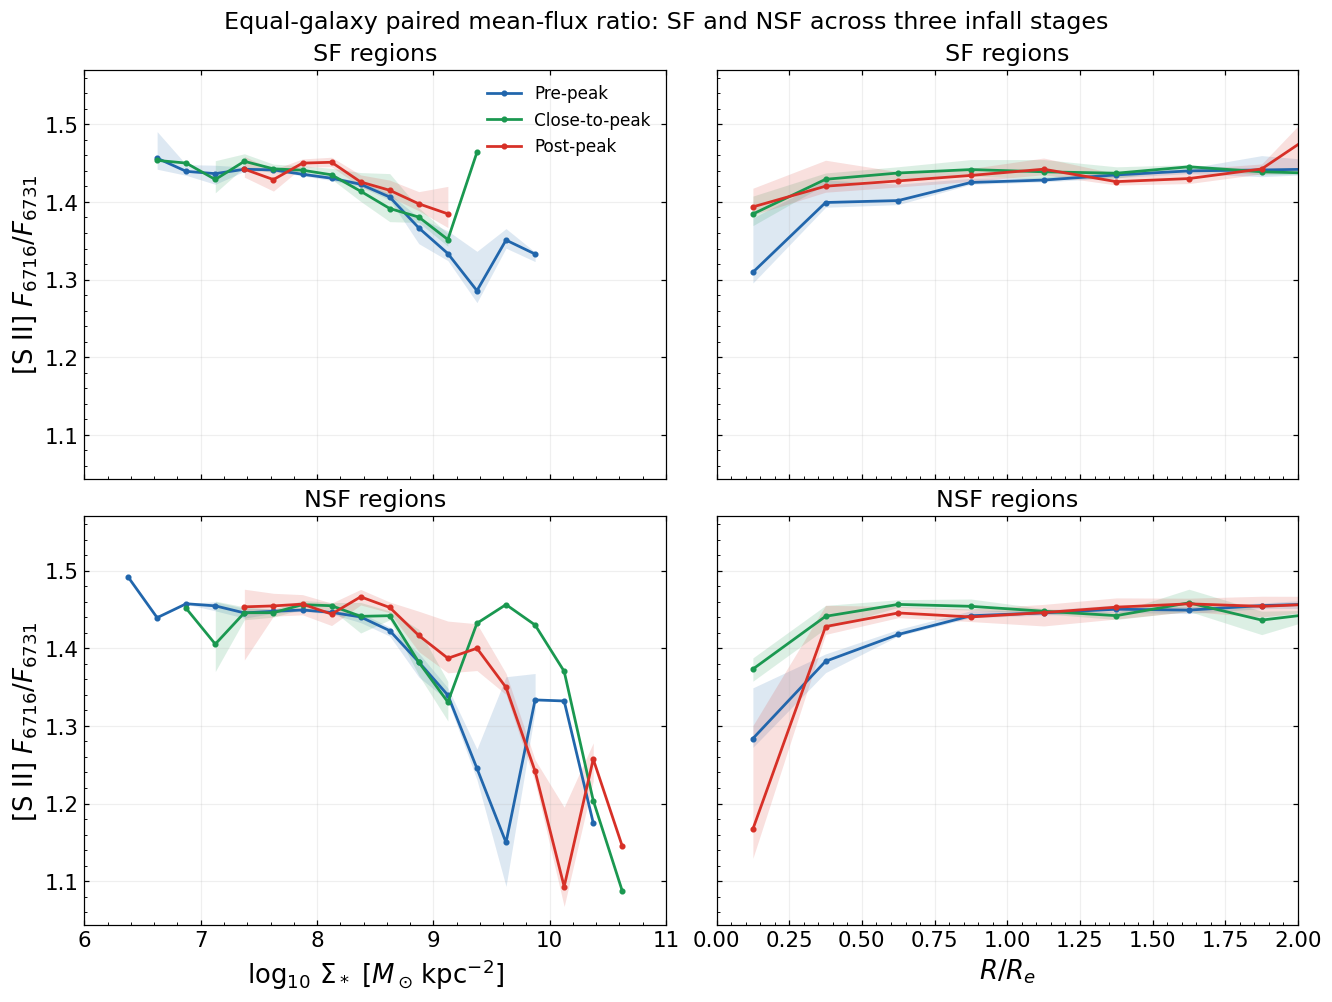

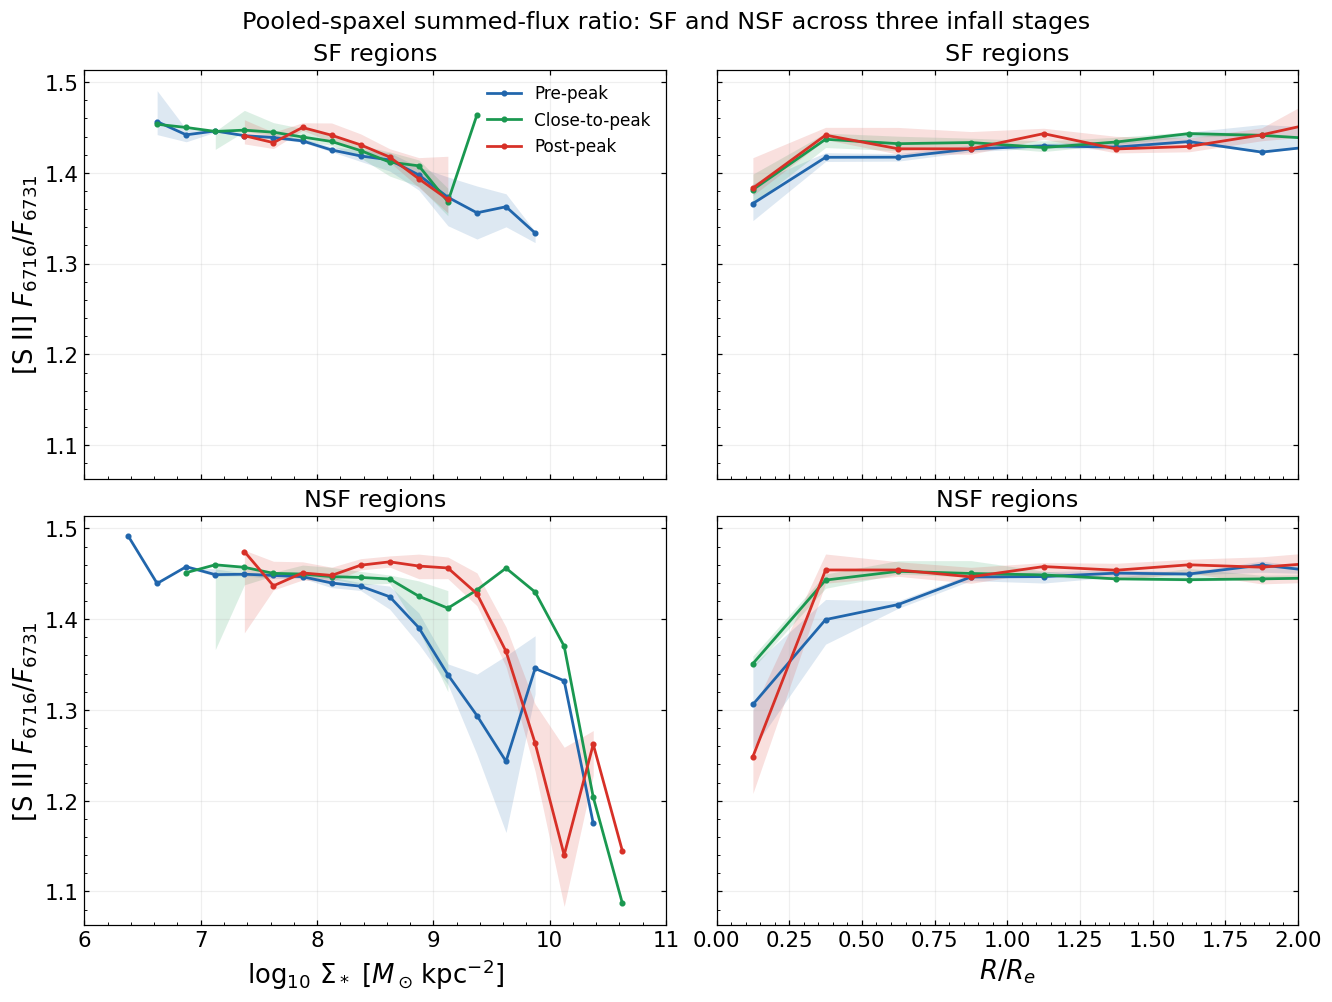

In [6]:
coordinate_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(len(CATEGORIES), 2, figsize=(12, 9), sharex='col', sharey=True, layout='constrained')
    for row, category in enumerate(CATEGORIES):
        for col, variable in enumerate(('log_sigma_star', 'radius_re')):
            ax = axes[row, col]
            no_support = []
            for stage in (1, 2, 3):
                p = ratio_profiles.loc[ratio_profiles.branch.eq(branch) & ratio_profiles.stage.eq(stage)
                    & ratio_profiles.category.eq(category) & ratio_profiles.variable.eq(variable)].sort_values('center')
                ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                        lw=1.8, label=STAGE_LABELS[stage])
                ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
                xmin, xmax = PROFILE_X_LIMITS[variable]
                if not p.loc[p.center.between(xmin, xmax), 'N_gal_support'].gt(0).any():
                    no_support.append(STAGE_LABELS[stage])
            if no_support:
                ax.text(0.03, 0.03, 'No supported bins: ' + ', '.join(no_support),
                        transform=ax.transAxes, va='bottom', fontsize=9, color='0.35')
            ax.set_title(category + ' regions')
            ax.set_xlim(PROFILE_X_LIMITS[variable])
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.2)
            if row == len(CATEGORIES) - 1:
                ax.set_xlabel(coordinate_labels[variable])
        axes[row, 0].set_ylabel(r'[S II] $F_{6716}/F_{6731}$')
    axes[0, 0].legend(frameon=False)
    label = 'Equal-galaxy paired mean-flux ratio' if branch == 'equal_galaxy' else 'Pooled-spaxel summed-flux ratio'
    fig.suptitle(label + ': SF and NSF across three infall stages')
    save_figure(fig, 'SII_doublet_ratio_SF_NSF_by_stage_' + branch)
    plt.show()
    plt.close(fig)

## VESTIGE XXI-style ratio distributions

Inspired by [VESTIGE XXI, Figs. 7-8](https://doi.org/10.1051/0004-6361/202659463)
and the supplied examples. Here the three infall stages replace the HI-deficiency
groups, and separate panels show SF and NSF. The x axis is the corrected
[S II] 6716/6731 ratio, **high to low from left to right**, to follow the
qualitative increasing-density direction. No electron-density conversion is used.
These are spaxel distributions, not catalogues of independently segmented HII
regions. VESTIGE's Halpha luminosity and size-quality cuts are not applied.

Plot the **equal-galaxy pair first**, then the **pooled-spaxel pair**.
Within each pair, the first figure shows all selected doublet detections. The second splits
the same sample into **inner R/Re<1** (filled, solid) and **outer R/Re>=1**
(open, dashed); equality belongs to the outer sample. Keep the full available
radial range, with no new radius or local/global mass cut.

For pooled-spaxel curves, each stage/catalogue has its own denominator N_total: all its selected spaxels,
including ratios outside the histogram or displayed x range. Both radial curves
use that same denominator; their linear probabilities sum bin by bin to the
all-radius distribution. This displays each radial population's contribution,
rather than independently normalizing away the relative inner/outer numbers.
The y axis is log10(N_bin/N_total), a bin fraction, not a density divided by bin
width. All panels use 0.025-wide bins from 0 to 2, display 1.6 down to 0.4, and
report out-of-grid and out-of-display counts. No ratio clipping or edge pile-up
is introduced. The earlier profile support thresholds do not filter these
distributions: every selected spaxel contributes.


For equal-galaxy curves, first normalize each product's histogram by that
product's full stage/catalogue spaxel count, then average those bin fractions
with equal product weights: p_j = mean_g(N_gj / N_g,total). Include products
with at least one selected doublet detection in the catalogue; products with
zero selected detections have no defined normalized distribution and are
excluded from this mean. Products with zero counts in an individual ratio bin
still contribute zero to that bin's mean. The eligible-product set does not
change across ratio bins or inner/outer samples. In each product, both radial
curves use that same full-product catalogue denominator, so the inner and
outer equal-galaxy curves also sum to the all-radius curve. NGC4567_8 receives
one weight, as in the earlier equal-galaxy profiles.

For both estimators, resample whole products within each stage with the same
bootstrap multiplicities. Equal-galaxy draws recompute the mean of eligible
normalized product histograms, counting repeated products with their sampled
multiplicity. Pooled-spaxel draws recompute the pooled numerator and denominator.
The two schemes differ in galaxy weighting, not in the bootstrap sampling unit.

Vertical bars show 16th-84th percentiles of 10,000 whole-product bootstrap
resamplings within each stage. Product multiplicities are shared across
catalogues, radial samples and estimators. The appropriate normalization is
recomputed in every draw.
These errors describe product sampling, not independent-spaxel Poisson errors
or line-flux measurement errors. Bins need at least two products with nonzero
bin counts for an error bar; one-product bins retain their central points.
Zero-count bins have no logarithmic point. Bounds reaching zero are displayed
at the plotting floor with a downward tick, not assigned a finite measured bound.
NGC4567_8 is still one bootstrap unit. Counts/support tables are retained below.
### Low-density saturation guide

At $T_e=10{,}000$ K, the supplied lookup table
`pyneb_sii_6716_6731_density_lookup_te8000_13000_step1000_ne20_100000_n4096.npz`
gives $F_{6716}/F_{6731}=1.4323317191$ at $n_e=20\,\mathrm{cm}^{-3}$.
Light-gray shading marks $F_{6716}/F_{6731}>1.4323317191$ in every
ratio-axis distribution panel: the low-density saturation regime associated
with $n_e<20\,\mathrm{cm}^{-3}$, on the left of the reversed ratio axis.
The table starts at 20 cm^-3; no densities below its grid are inferred.
Ratios beyond the physical low-density limit are also shaded as part of this
low-density/out-of-range guide. Shading does not exclude any measurements.


In [7]:
def normalized_histogram_bootstrap(histograms, totals, multiplicities, branch='pooled_spaxel'):
    """Bin fractions with pooled-spaxel or equal-product central and bootstrap weights."""
    histograms = np.asarray(histograms, dtype=float)
    totals = np.asarray(totals, dtype=float)
    assert histograms.ndim == 2 and histograms.shape[0] == len(totals)
    assert np.all(histograms >= 0) and np.all(totals >= 0)
    assert np.all(histograms.sum(axis=1) <= totals)
    if branch == 'equal_galaxy':
        eligible = totals > 0
        values = np.divide(histograms, totals[:, None], out=np.zeros_like(histograms),
                           where=totals[:, None] > 0)
        weights = eligible.astype(float)
    elif branch == 'pooled_spaxel':
        values, weights = histograms, totals
    else:
        raise ValueError(f'Unknown distribution estimator: {branch}')
    central = values.sum(axis=0) / weights.sum() if weights.sum() else np.full(histograms.shape[1], np.nan)
    # Direct sums avoid spurious floating-point warnings from the local matmul backend.
    boot_denominator = np.einsum('bg,g->b', multiplicities, weights, optimize=False)
    boot_numerator = np.einsum('bg,gj->bj', multiplicities, values, optimize=False)
    boot = np.divide(boot_numerator, boot_denominator[:, None],
        out=np.full((len(multiplicities), histograms.shape[1]), np.nan), where=boot_denominator[:, None] > 0)
    finite_draws = boot_denominator > 0
    assert np.isfinite(boot[finite_draws]).all()
    assert np.all((boot[finite_draws] >= 0) & (boot[finite_draws] <= 1 + 1e-12))
    return central, boot, finite_draws

distribution_rows, histogram_qc_rows = [], []
for stage in (1, 2, 3):
    ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(ids)
    rng = np.random.default_rng(RANDOM_SEED + 23_000_000 + stage)
    multiplicities = (rng.multinomial(g, np.full(g, 1 / g), size=N_BOOTSTRAP)
                      if g else np.empty((N_BOOTSTRAP, 0), dtype=int))
    for category in CATEGORIES:
        region_probabilities = {branch: {} for branch in ('equal_galaxy', 'pooled_spaxel')}
        for region in ('all', 'inner', 'outer'):
            panel = ratio_histograms_by_galaxy.loc[
                ratio_histograms_by_galaxy.stage.eq(stage)
                & ratio_histograms_by_galaxy.category.eq(category)
                & ratio_histograms_by_galaxy.region.eq(region)
            ].set_index('galaxy').reindex(ids)
            assert panel.N_total.notna().all()
            histograms = np.stack(panel['hist'].to_list()) if g else np.empty((0, len(RATIO_HIST_EDGES) - 1))
            totals = panel.N_total.to_numpy(float)
            support = (histograms > 0).sum(axis=0)
            for branch in ('equal_galaxy', 'pooled_spaxel'):
                central, boot, valid_draws = normalized_histogram_bootstrap(histograms, totals, multiplicities, branch)
                region_probabilities[branch][region] = central
                bounds = np.percentile(boot[valid_draws], [16, 84], axis=0) if valid_draws.any() else np.full((2, histograms.shape[1]), np.nan)
                bounds[:, support < 2] = np.nan
                for j, (lo, hi) in enumerate(zip(RATIO_HIST_EDGES[:-1], RATIO_HIST_EDGES[1:])):
                    distribution_rows.append(dict(branch=branch, stage=stage, category=category, region=region,
                        left=lo, right=hi, center=(lo + hi) / 2, N_bin=int(histograms[:, j].sum()),
                        N_total=int(totals.sum()), N_products_normalized=int((totals > 0).sum()),
                        N_products_in_bin=int(support[j]), N_finite_draws=int(valid_draws.sum()),
                        probability=central[j], lo=bounds[0, j], hi=bounds[1, j]))
            histogram_qc_rows.append(dict(stage=STAGE_LABELS[stage], category=category, region=region,
                N_total=int(totals.sum()), N_products_normalized=int((totals > 0).sum()),
                N_products_excluded_empty=int((totals == 0).sum()), N_region=int(panel.N_region.sum()),
                N_in_grid=int(histograms.sum()), N_below_grid=int(panel.N_below_grid.sum()),
                N_above_grid=int(panel.N_above_grid.sum()),
                N_outside_display_all_radii=int(panel.N_outside_display.sum()),
                N_products_with_region=int(panel.N_region.gt(0).sum())))
        for branch in ('equal_galaxy', 'pooled_spaxel'):
            probabilities = region_probabilities[branch]
            if np.isfinite(probabilities['all']).any():
                assert np.allclose(probabilities['all'], probabilities['inner'] + probabilities['outer'])

ratio_distributions = pd.DataFrame(distribution_rows)
histogram_qc = pd.DataFrame(histogram_qc_rows)
assert len(ratio_distributions) == 2 * 3 * len(CATEGORIES) * 3 * (len(RATIO_HIST_EDGES) - 1)
assert not ratio_distributions.duplicated(['branch', 'stage', 'category', 'region', 'left']).any()
assert (histogram_qc.N_region == histogram_qc.N_in_grid + histogram_qc.N_below_grid + histogram_qc.N_above_grid).all()
assert ratio_distributions.loc[ratio_distributions.N_products_in_bin.lt(2), ['lo', 'hi']].isna().all().all()
display(histogram_qc)
display(ratio_distributions.groupby(['branch', 'stage', 'category', 'region'])[['N_bin', 'probability']].sum())
print('Both estimators: normalization, radial partition, histogram tails and product support checks passed.')

,stage,category,region,N_total,N_products_normalized,N_products_excluded_empty,N_region,N_in_grid,N_below_grid,N_above_grid,N_outside_display_all_radii,N_products_with_region
0,Pre-peak,SF,all,1412363,8,0,1412363,1411557,0,806,66406,8
1,Pre-peak,SF,inner,1412363,8,0,728754,727948,0,806,66406,8
2,Pre-peak,SF,outer,1412363,8,0,683609,683609,0,0,66406,8
3,Pre-peak,NSF,all,805528,8,0,805528,798522,0,7006,117509,8
4,Pre-peak,NSF,inner,805528,8,0,499223,492369,0,6854,117509,8
5,Pre-peak,NSF,outer,805528,8,0,306305,306153,0,152,117509,8
6,Close-to-peak,SF,all,713550,5,0,713550,713145,0,405,42867,5
7,Close-to-peak,SF,inner,713550,5,0,272023,271686,0,337,42867,5
8,Close-to-peak,SF,outer,713550,5,0,441527,441459,0,68,42867,4
9,Close-to-peak,NSF,all,457952,5,0,457952,452048,0,5904,78020,5


N_bin  probability
branch        stage category region                      
equal_galaxy  1     NSF      all      798522     0.995019
                             inner    492369     0.536314
                             outer    306153     0.458705
                    SF       all     1411557     0.999651
                             inner    727948     0.521448
                             outer    683609     0.478203
              2     NSF      all      452048     0.987124
                             inner    173408     0.527177
                             outer    278640     0.459947
                    SF       all      713145     0.999597
                             inner    271686     0.634127
                             outer    441459     0.365470
              3     NSF      all      576541     0.956013
                             inner    382052     0.726511
                             outer    194489     0.229502
                    SF       all      189222     0.992134
                             inner    138549     0.681676
                             outer     50673     0.310459
pooled_spaxel 1     NSF      all      798522     0.991303
                             inner    492369     0.611238
                             outer    306153     0.380065
                    SF       all     1411557     0.999429
                             inner    727948     0.515411
                             outer    683609     0.484018
              2     NSF      all      452048     0.987108
                             inner    173408     0.378660
                             outer    278640     0.608448
                    SF       all      713145     0.999432
                             inner    271686     0.380753
                             outer    441459     0.618680
              3     NSF      all      576541     0.957259
                             inner    382052     0.634340
                             outer    194489     0.322920
                    SF       all      189222     0.996382
                             inner    138549     0.729555
                             outer     50673     0.266828

Both estimators: normalization, radial partition, histogram tails and product support checks passed.


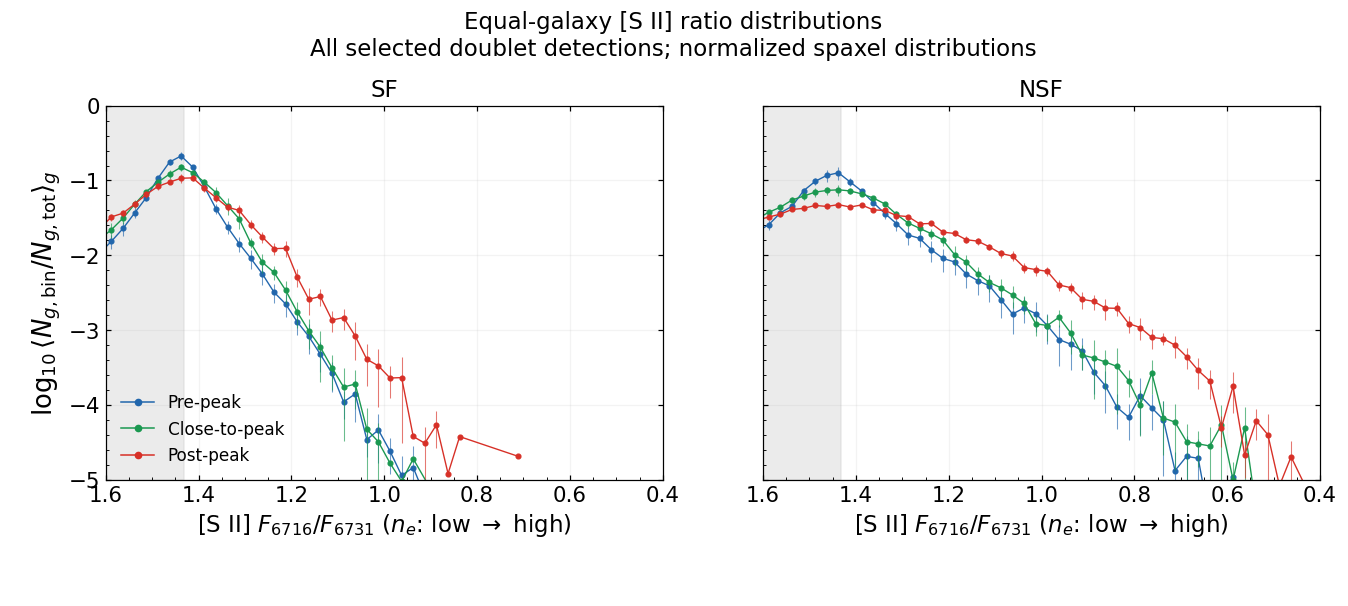

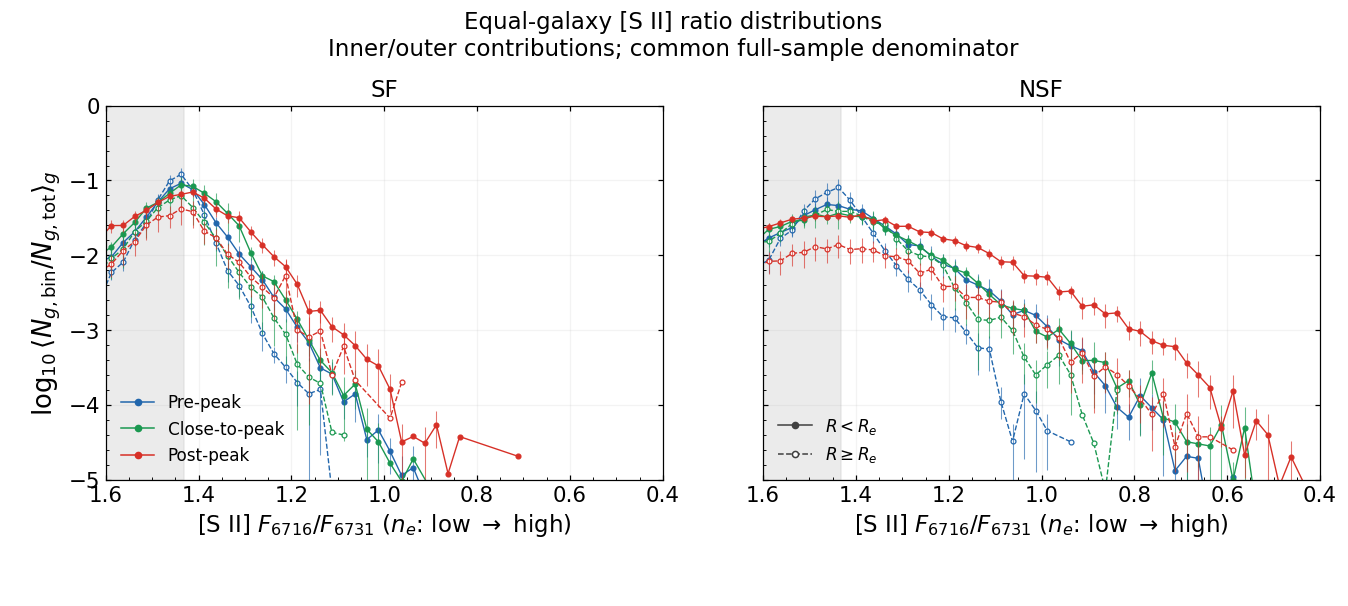

In [8]:
from matplotlib.lines import Line2D

def draw_ratio_distribution(ax, panel, color, filled, linestyle, label=None):
    positive = panel.loc[panel.probability.gt(0)].sort_values('center')
    if positive.empty:
        return
    x = positive.center.to_numpy(float)
    y = np.log10(positive.probability.to_numpy(float))
    ax.plot(x, y, color=color, marker='o', ms=3.2, lw=0.9, ls=linestyle,
            markerfacecolor=color if filled else 'white', markeredgewidth=0.8, label=label)
    band = positive.loc[positive.N_products_in_bin.ge(2) & positive.lo.notna() & positive.hi.gt(0)]
    if len(band):
        floor = 10.0 ** RATIO_HIST_LOG_LIMITS[0]
        lower = np.log10(np.maximum(band.lo.to_numpy(float), floor))
        upper = np.log10(np.maximum(band.hi.to_numpy(float), floor))
        ax.vlines(band.center, lower, upper, color=color, lw=0.7, alpha=0.65)
        zero_bound = band.lo.le(0)
        ax.plot(band.loc[zero_bound, 'center'], np.full(int(zero_bound.sum()), RATIO_HIST_LOG_LIMITS[0]),
                marker='v', ms=3, linestyle='none', color=color, clip_on=False)



def plot_ratio_distributions(branch):
    for radial_split in (False, True):
        fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(12, 5.4), sharex=True, sharey=True)
        fig.subplots_adjust(left=0.07, right=0.99, bottom=0.19, top=0.82, wspace=0.18)
        for ax, category in zip(axes, CATEGORIES):
            for stage in (1, 2, 3):
                regions = ('inner', 'outer') if radial_split else ('all',)
                for region in regions:
                    panel = ratio_distributions.loc[ratio_distributions.branch.eq(branch) & ratio_distributions.stage.eq(stage)
                        & ratio_distributions.category.eq(category) & ratio_distributions.region.eq(region)]
                    draw_ratio_distribution(ax, panel, STAGE_COLORS[stage], filled=region != 'outer',
                        linestyle='--' if region == 'outer' else '-', label=STAGE_LABELS[stage] if region != 'outer' else None)
            ax.set_title(category, fontsize=15)
            ax.set_xlim(RATIO_HIST_X_LIMITS)
            ax.axvspan(SII_SATURATION_RATIO, max(RATIO_HIST_X_LIMITS),
                       color='lightgray', alpha=0.45, zorder=0)
            ax.set_ylim(RATIO_HIST_LOG_LIMITS)
            ax.set_xlabel(r'[S II] $F_{6716}/F_{6731}$ ($n_e$: low $\rightarrow$ high)', fontsize=15)
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.15)
        ylabel = (r'$\log_{10}\langle N_{g,\rm bin}/N_{g,\rm tot}\rangle_g$'
                  if branch == 'equal_galaxy' else r'$\log_{10}(N_{\rm bin}/N_{\rm tot})$')
        axes[0].set_ylabel(ylabel)
        stage_handles = [Line2D([], [], color=STAGE_COLORS[s], marker='o', ms=4, lw=1, label=STAGE_LABELS[s]) for s in (1, 2, 3)]
        axes[0].legend(handles=stage_handles, frameon=False, loc='lower left')
        if radial_split:
            radius_handles = [Line2D([], [], color='0.25', marker='o', ms=4, lw=1, ls='-', label=r'$R<R_e$'),
                Line2D([], [], color='0.25', marker='o', markerfacecolor='white', ms=4, lw=1, ls='--', label=r'$R\geq R_e$')]
            axes[-1].legend(handles=radius_handles, frameon=False, loc='lower left')
        title = 'Inner/outer contributions; common full-sample denominator' if radial_split else 'All selected doublet detections; normalized spaxel distributions'
        estimator = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
        fig.suptitle(estimator + ' [S II] ratio distributions\n' + title, fontsize=15)
        save_figure(fig, 'SII_ratio_distribution_by_stage_' + branch + '_' + ('inner_outer' if radial_split else 'all_radii'))
        plt.show()
        plt.close(fig)

# Equal-galaxy pair comes before the pooled-spaxel pair.
plot_ratio_distributions('equal_galaxy')

## Pooled-spaxel distributions
Retain the original pooled-spaxel estimator and whole-product bootstrap for comparison.


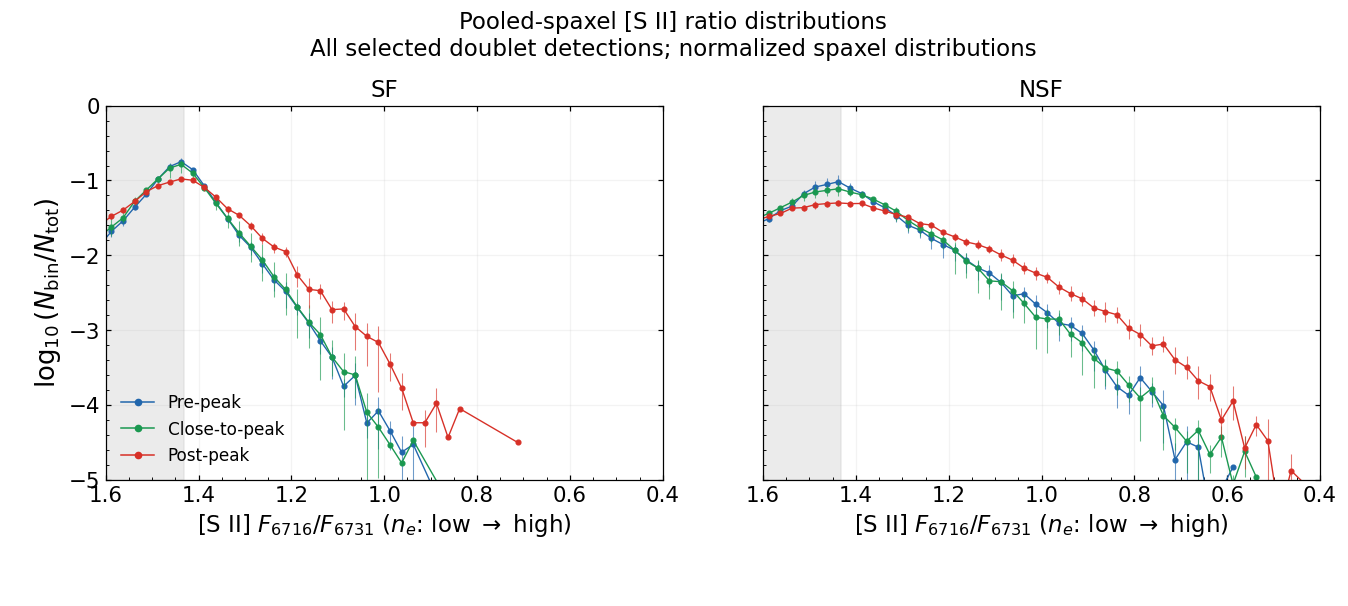

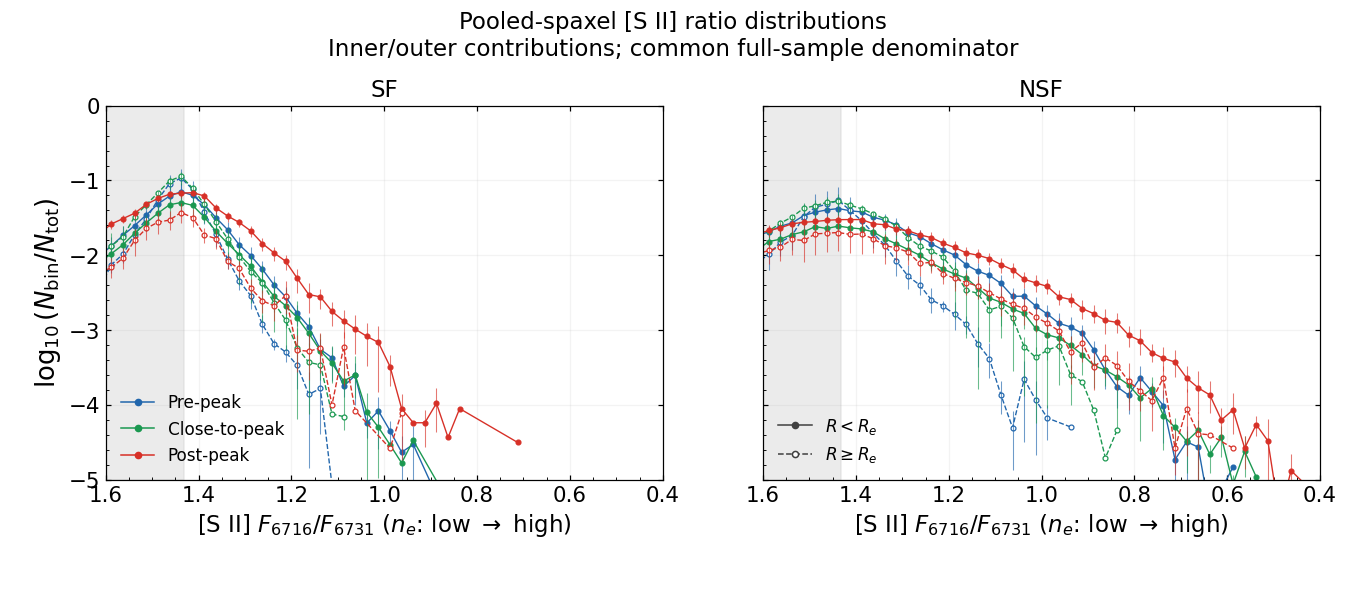

In [9]:
plot_ratio_distributions('pooled_spaxel')

## Distributions within stellar surface-density and radial bins

Normalize **each spatial bin separately**, as requested. Mass and radius are
two separate splits, not a joint grid of mass-radius selections. Mass means
local log10 stellar surface density in Msun/kpc^2, not total galaxy mass.

- Local log Sigma_star: <7.5; 7.5<=x<8.5; 8.5<=x<=9.5; >9.5.
- Radius R/Re: 0<=x<0.5; 0.5<=x<1; 1<=x<=1.5; >1.5.

Within each stage/catalogue/spatial bin, the pooled-spaxel distribution is
sum_g(N_gj)/sum_g(N_g,bin). The equal-galaxy distribution is the mean of
N_gj/N_g,bin over products with at least one selected doublet detection in that
spatial bin. Products empty in that bin are excluded from the mean; an eligible
product with zero counts in a particular ratio bin contributes zero there.
Consequently the galaxy set can differ between spatial bins. Report those
counts explicitly. Full bin denominators include ratio tails beyond the
histogram grid or display range, just as for the earlier distributions.

Keep all existing selection cuts and the same 10,000 whole-product bootstrap
draws within each stage, shared across spatial bins, catalogues and estimators.
Recompute each spatial-bin normalization per draw. Use 16th-84th percentiles;
retain the earlier rule of requiring two contributing products in a ratio bin
for error bars. No profile-only 50/20-spaxel support gate is introduced here.
NGC4567_8 remains one product/bootstrap unit.

Four new 2x4 figures follow: equal-galaxy mass and radius splits first, then
pooled-spaxel mass and radius splits. Rows are SF and NSF; columns are
the four spatial bins; curves are the three infall stages. Ratio axes continue
from high to low. These conditional distributions compare shapes; the four
separately normalized curves are not additive contributions to the parent.

In [10]:
# Verify that the four spatial bins account for every selected parent spaxel.
for keys, panel in stratified_histograms_by_galaxy.groupby(['galaxy', 'category', 'variable']):
    assert len(panel) == 4 and panel.N_parent.nunique() == 1
    assert panel.N_total.sum() == panel.N_parent.iloc[0]

stratified_rows, stratified_qc_rows = [], []
for stage in (1, 2, 3):
    ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(ids)
    rng = np.random.default_rng(RANDOM_SEED + 23_000_000 + stage)
    multiplicities = (rng.multinomial(g, np.full(g, 1 / g), size=N_BOOTSTRAP)
                      if g else np.empty((N_BOOTSTRAP, 0), dtype=int))
    for category in CATEGORIES:
        for variable in STRATUM_LABELS:
            for stratum in range(4):
                panel = stratified_histograms_by_galaxy.loc[
                    stratified_histograms_by_galaxy.stage.eq(stage)
                    & stratified_histograms_by_galaxy.category.eq(category)
                    & stratified_histograms_by_galaxy.variable.eq(variable)
                    & stratified_histograms_by_galaxy.stratum.eq(stratum)
                ].set_index('galaxy').reindex(ids)
                assert panel.N_total.notna().all()
                hist = np.stack(panel['hist'].to_list()) if g else np.empty((0, len(RATIO_HIST_EDGES) - 1))
                totals = panel.N_total.to_numpy(float)
                support = (hist > 0).sum(axis=0)
                eligible = totals > 0
                for branch in ('equal_galaxy', 'pooled_spaxel'):
                    central, boot, valid_draws = normalized_histogram_bootstrap(hist, totals, multiplicities, branch)
                    bounds = (np.percentile(boot[valid_draws], [16, 84], axis=0) if valid_draws.any()
                              else np.full((2, hist.shape[1]), np.nan))
                    bounds[:, support < 2] = np.nan
                    if eligible.any():
                        assert np.isfinite(central).all() and np.all(central >= 0)
                        expected = ((hist[eligible] / totals[eligible, None]).mean(axis=0)
                                    if branch == 'equal_galaxy' else hist.sum(axis=0) / totals.sum())
                        assert np.allclose(central, expected)
                        tail = panel.N_below_grid.to_numpy(float) + panel.N_above_grid.to_numpy(float)
                        missing = ((tail[eligible] / totals[eligible]).mean() if branch == 'equal_galaxy'
                                   else tail.sum() / totals.sum())
                        assert np.isclose(central.sum() + missing, 1.0)
                    else:
                        assert np.isnan(central).all() and not valid_draws.any()
                    for j, (lo, hi) in enumerate(zip(RATIO_HIST_EDGES[:-1], RATIO_HIST_EDGES[1:])):
                        stratified_rows.append(dict(branch=branch, stage=stage, category=category,
                            variable=variable, stratum=stratum, left=lo, right=hi, center=(lo + hi) / 2,
                            N_bin=int(hist[:, j].sum()), N_total=int(totals.sum()),
                            N_products_normalized=int(eligible.sum()), N_products_in_bin=int(support[j]),
                            N_finite_draws=int(valid_draws.sum()), probability=central[j], lo=bounds[0, j], hi=bounds[1, j]))
                stratified_qc_rows.append(dict(stage=STAGE_LABELS[stage], category=category,
                    variable=variable, stratum=stratum, label=STRATUM_LABELS[variable][stratum],
                    N_total=int(totals.sum()), N_products_normalized=int(eligible.sum()),
                    N_products_excluded_empty=int((~eligible).sum()), N_in_grid=int(hist.sum()),
                    N_below_grid=int(panel.N_below_grid.sum()), N_above_grid=int(panel.N_above_grid.sum()),
                    N_outside_display=int(panel.N_outside_display.sum())))

stratified_ratio_distributions = pd.DataFrame(stratified_rows)
stratified_histogram_qc = pd.DataFrame(stratified_qc_rows)
assert len(stratified_ratio_distributions) == 2 * 3 * len(CATEGORIES) * 2 * 4 * (len(RATIO_HIST_EDGES) - 1)
assert not stratified_ratio_distributions.duplicated(['branch', 'stage', 'category', 'variable', 'stratum', 'left']).any()
assert (stratified_histogram_qc.N_total == stratified_histogram_qc.N_in_grid
        + stratified_histogram_qc.N_below_grid + stratified_histogram_qc.N_above_grid).all()
assert stratified_ratio_distributions.loc[stratified_ratio_distributions.N_products_in_bin.lt(2), ['lo', 'hi']].isna().all().all()
display(stratified_histogram_qc)
print('Spatial partitions, separate-bin normalization, both estimators, ratio tails and empty strata verified.')

,stage,category,variable,stratum,label,N_total,N_products_normalized,N_products_excluded_empty,N_in_grid,N_below_grid,N_above_grid,N_outside_display
0,Pre-peak,SF,log_sigma_star,0,$\log\Sigma_*<7.5$,128136,7,1,128136,0,0,942
1,Pre-peak,SF,log_sigma_star,1,$7.5\leq\log\Sigma_*<8.5$,1143059,8,0,1142382,0,677,55021
2,Pre-peak,SF,log_sigma_star,2,$8.5\leq\log\Sigma_*\leq9.5$,140193,8,0,140065,0,128,10392
3,Pre-peak,SF,log_sigma_star,3,$\log\Sigma_*>9.5$,975,6,2,974,0,1,51
4,Pre-peak,SF,radius_re,0,$0\leq R/R_e<0.5$,169623,8,0,169087,0,536,18486
5,Pre-peak,SF,radius_re,1,$0.5\leq R/R_e<1$,559131,8,0,558861,0,270,33750
6,Pre-peak,SF,radius_re,2,$1\leq R/R_e\leq1.5$,395946,8,0,395946,0,0,10570
7,Pre-peak,SF,radius_re,3,$R/R_e>1.5$,287663,7,1,287663,0,0,3600
8,Pre-peak,NSF,log_sigma_star,0,$\log\Sigma_*<7.5$,79585,7,1,79585,0,0,2362
9,Pre-peak,NSF,log_sigma_star,1,$7.5\leq\log\Sigma_*<8.5$,629210,8,0,625308,0,3902,93437


Spatial partitions, separate-bin normalization, both estimators, ratio tails and empty strata verified.


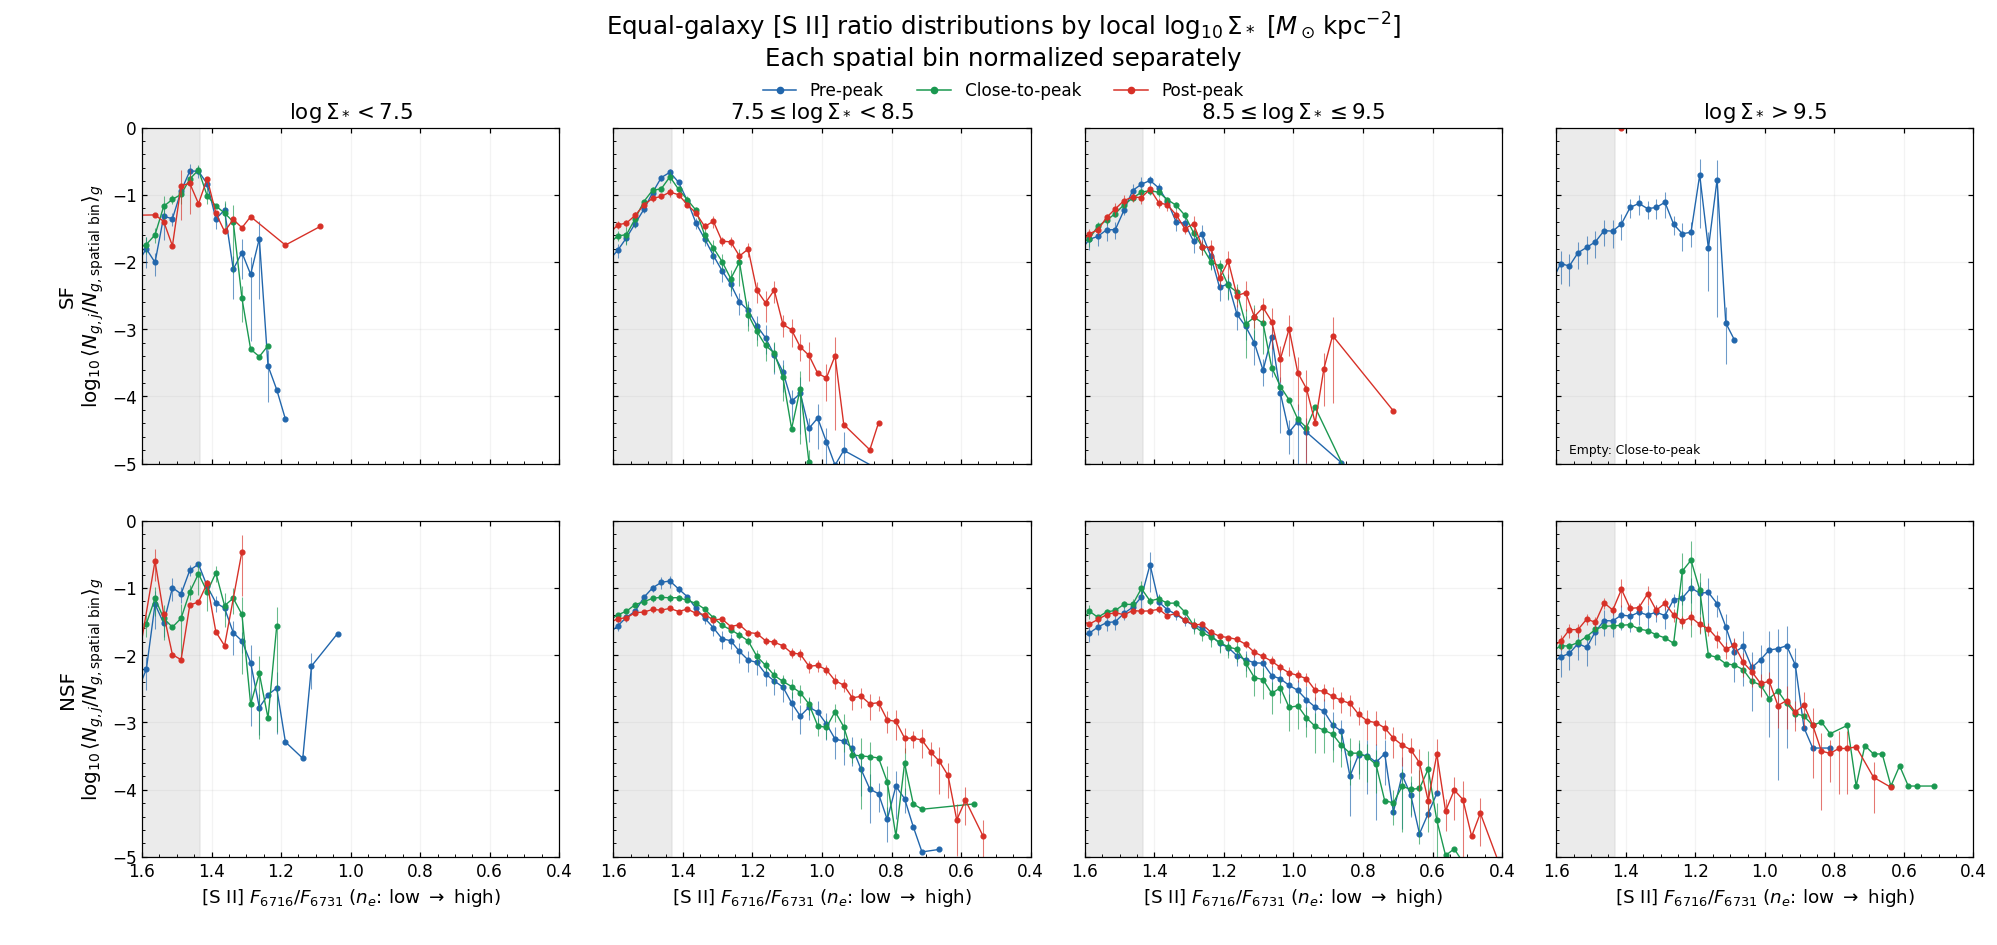

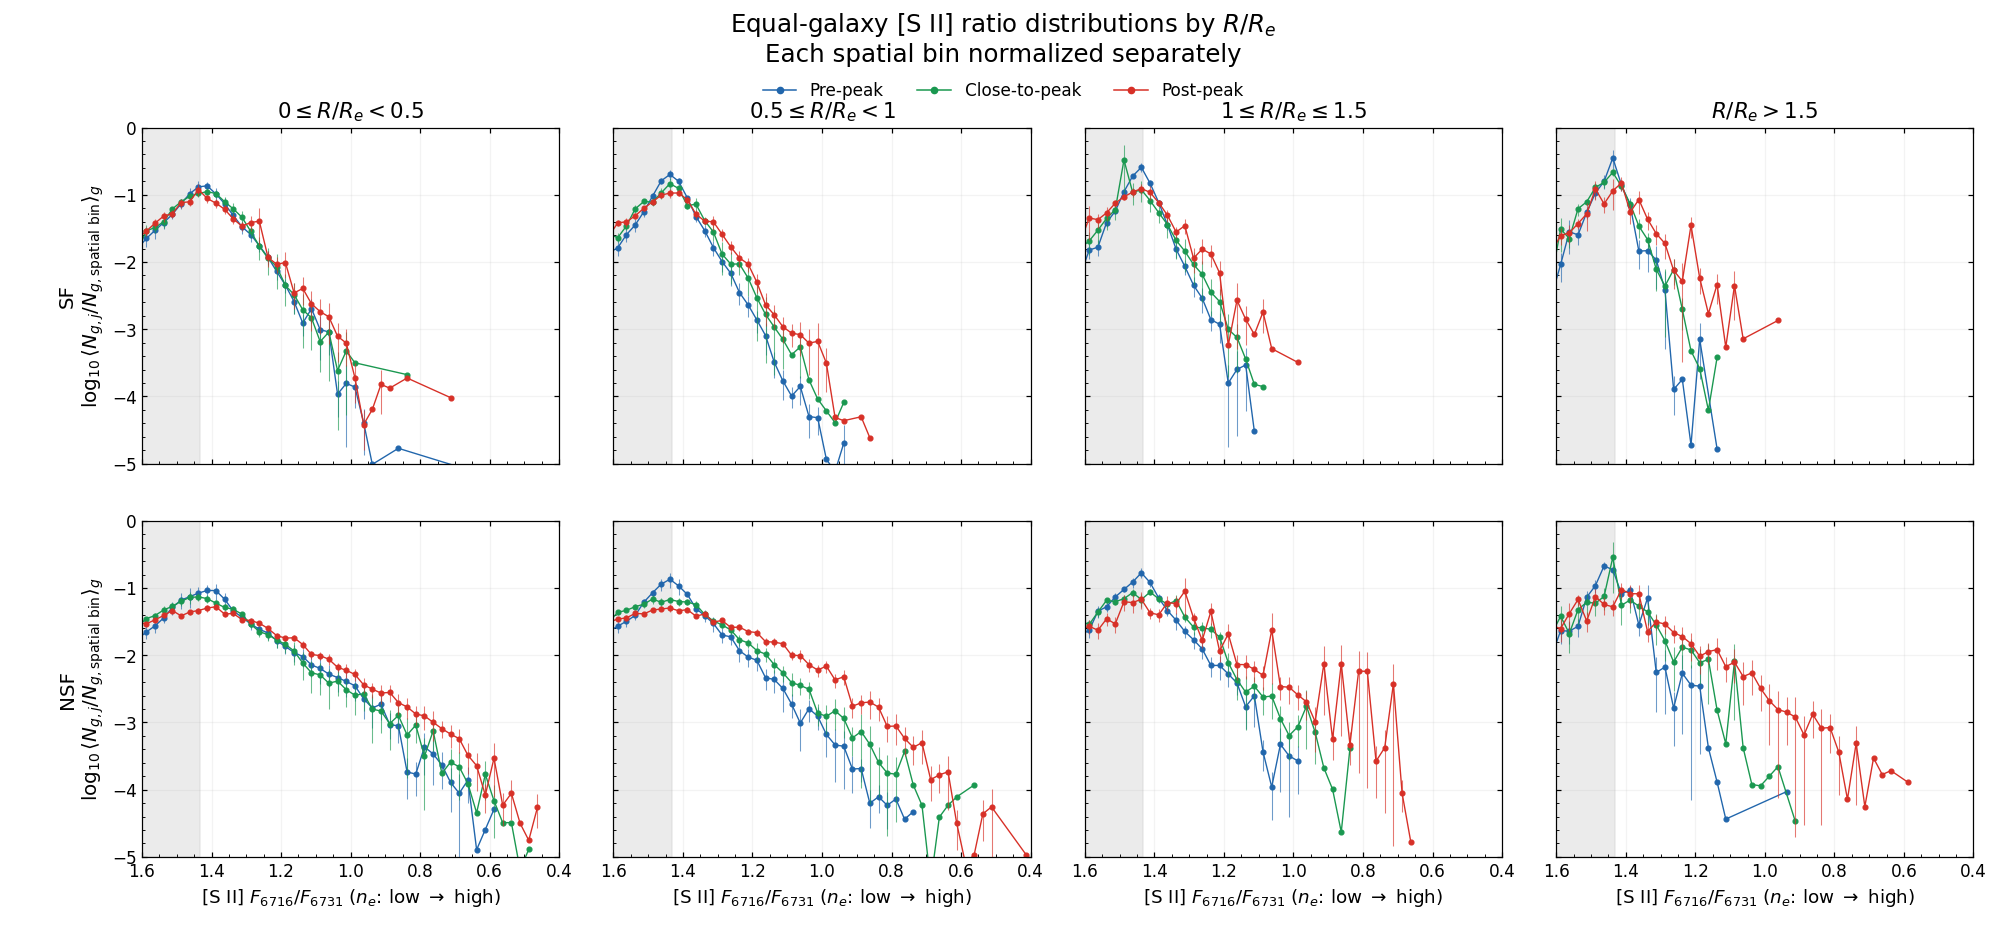

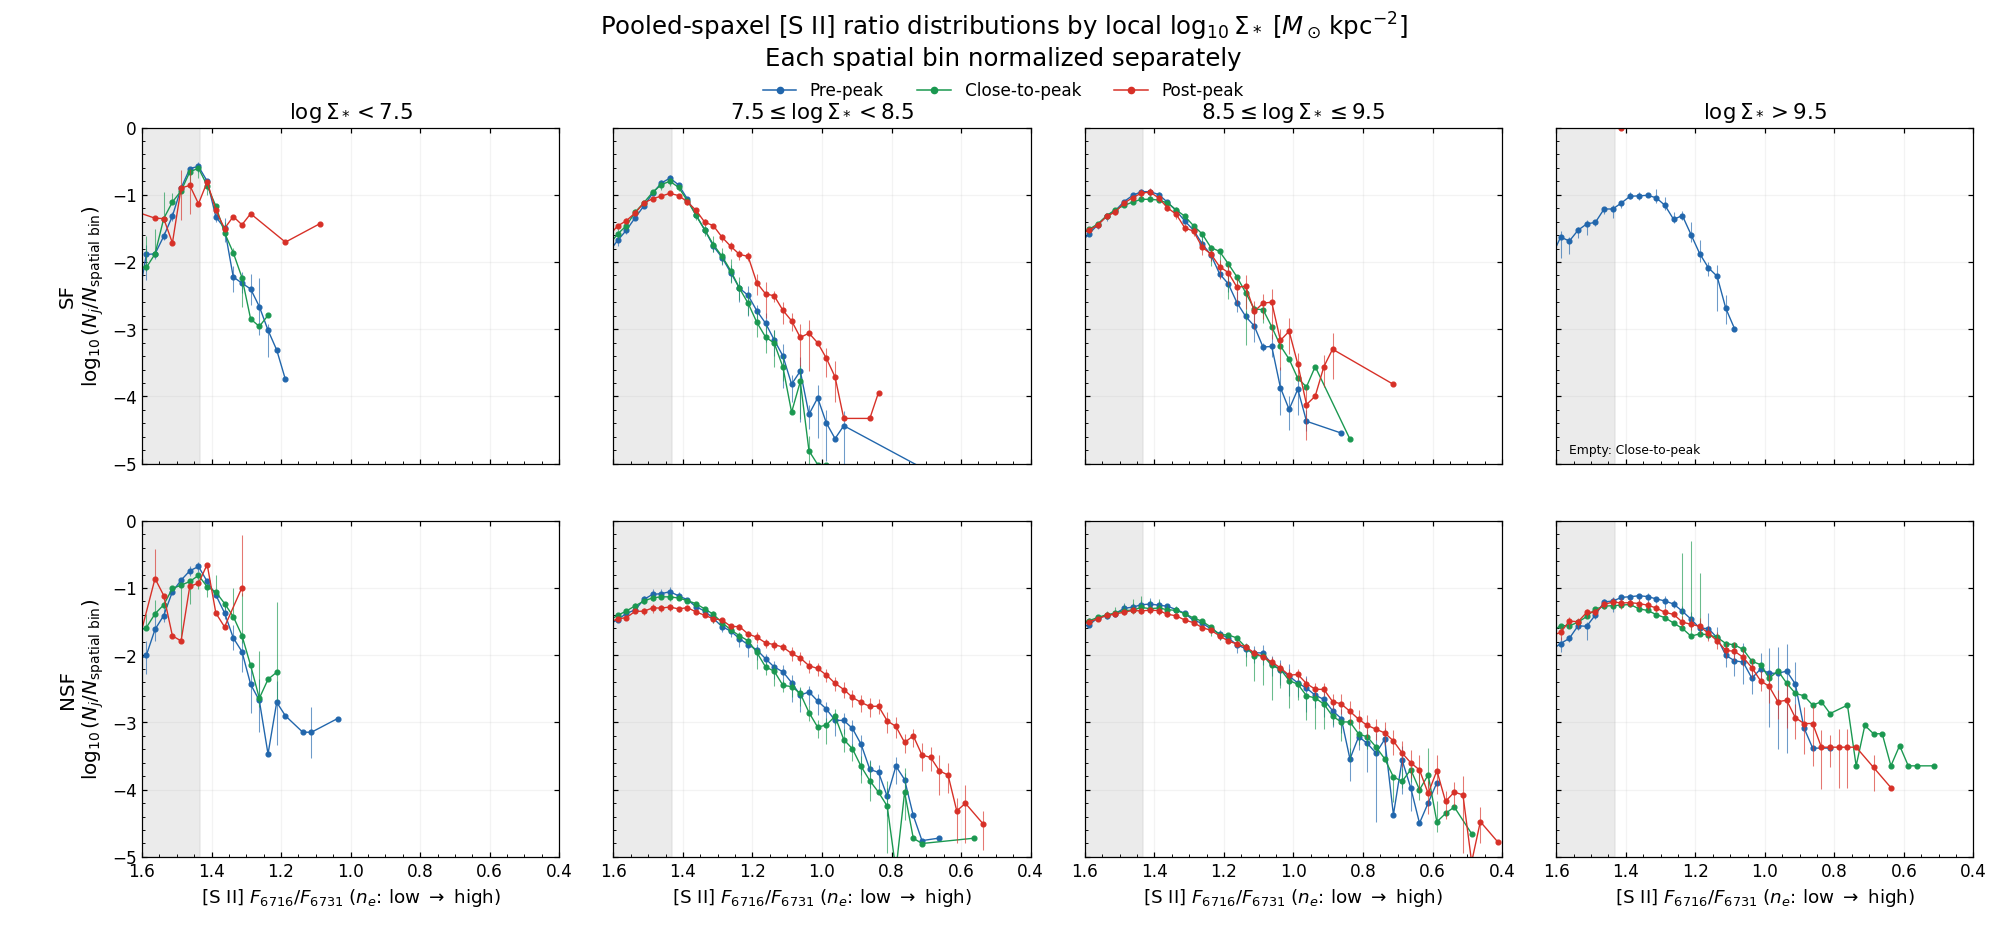

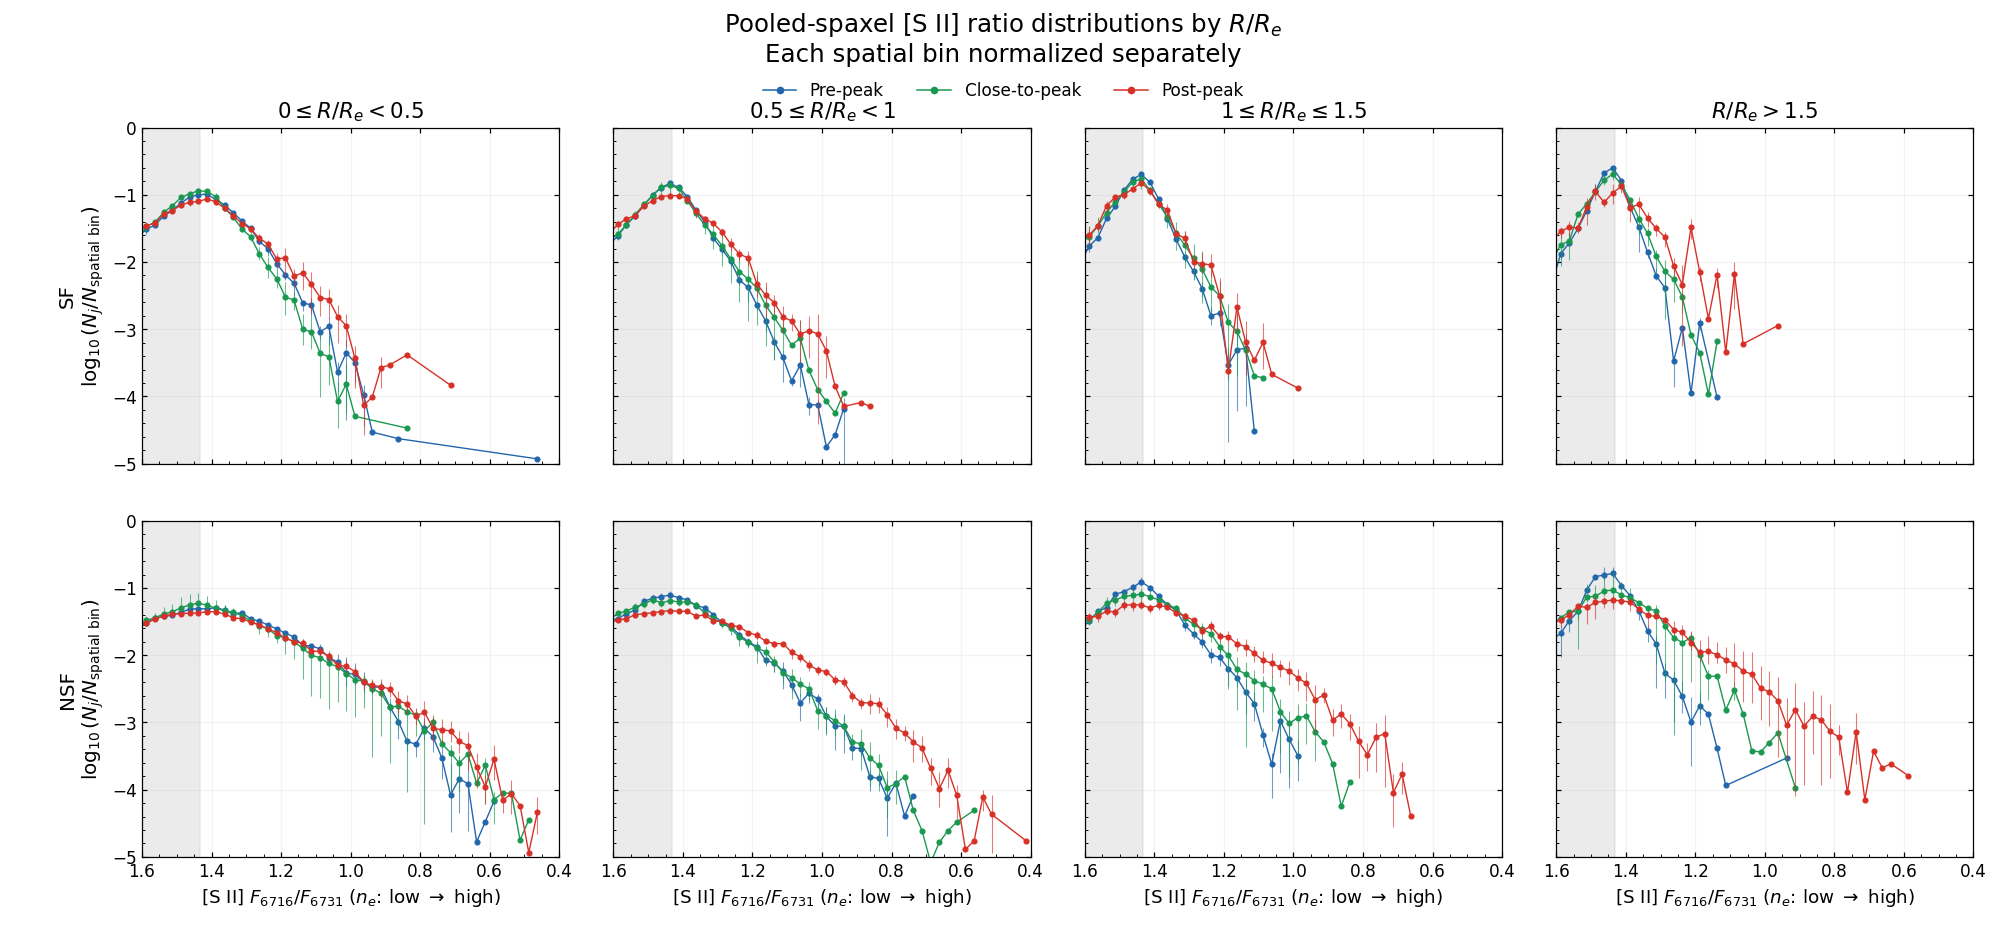

In [11]:
def plot_stratified_ratio_distributions(branch, variable):
    fig, axes = plt.subplots(len(CATEGORIES), 4, figsize=(18, 8.5), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.065, right=0.99, bottom=0.08, top=0.86, wspace=0.13, hspace=0.17)
    for row, category in enumerate(CATEGORIES):
        for stratum in range(4):
            ax = axes[row, stratum]
            no_sample = []
            for stage in (1, 2, 3):
                panel = stratified_ratio_distributions.loc[
                    stratified_ratio_distributions.branch.eq(branch)
                    & stratified_ratio_distributions.variable.eq(variable)
                    & stratified_ratio_distributions.stratum.eq(stratum)
                    & stratified_ratio_distributions.category.eq(category)
                    & stratified_ratio_distributions.stage.eq(stage)]
                draw_ratio_distribution(ax, panel, STAGE_COLORS[stage], filled=True, linestyle='-')
                if not panel.N_total.gt(0).any():
                    no_sample.append(STAGE_LABELS[stage])
            if no_sample:
                ax.text(0.03, 0.03, 'Empty: ' + ', '.join(no_sample), transform=ax.transAxes, fontsize=8)
            if row == 0:
                ax.set_title(STRATUM_LABELS[variable][stratum], fontsize=14)
            if stratum == 0:
                ax.set_ylabel(category + '\n' + (r'$\log_{10}\langle N_{g,j}/N_{g,\rm spatial\ bin}\rangle_g$'
                    if branch == 'equal_galaxy' else r'$\log_{10}(N_j/N_{\rm spatial\ bin})$'), fontsize=13)
            if row == len(CATEGORIES) - 1:
                ax.set_xlabel(r'[S II] $F_{6716}/F_{6731}$ ($n_e$: low $\rightarrow$ high)', fontsize=12)
            ax.set_xlim(RATIO_HIST_X_LIMITS)
            ax.axvspan(SII_SATURATION_RATIO, max(RATIO_HIST_X_LIMITS),
                       color='lightgray', alpha=0.45, zorder=0)
            ax.set_ylim(RATIO_HIST_LOG_LIMITS)
            ax.tick_params(top=True, right=True, labelsize=11)
            ax.minorticks_on()
            ax.grid(alpha=0.15)
    handles = [Line2D([], [], color=STAGE_COLORS[s], marker='o', ms=4, lw=1, label=STAGE_LABELS[s]) for s in (1, 2, 3)]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.925), ncol=3, frameon=False)
    estimator = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    split_label = r'local $\log_{10}\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]' if variable == 'log_sigma_star' else r'$R/R_e$'
    fig.suptitle(estimator + ' [S II] ratio distributions by ' + split_label
                 + '\nEach spatial bin normalized separately', fontsize=16, y=0.985)
    save_figure(fig, 'SII_ratio_distribution_' + branch + '_by_' + variable)
    plt.show()
    plt.close(fig)

for branch in ('equal_galaxy', 'pooled_spaxel'):
    for variable in ('log_sigma_star', 'radius_re'):
        plot_stratified_ratio_distributions(branch, variable)